<a href="https://colab.research.google.com/github/angelpavu/A04-clustering/blob/main/notebook_(5).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Angel Pavu

**Date:** 10/14/2026

In [1]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

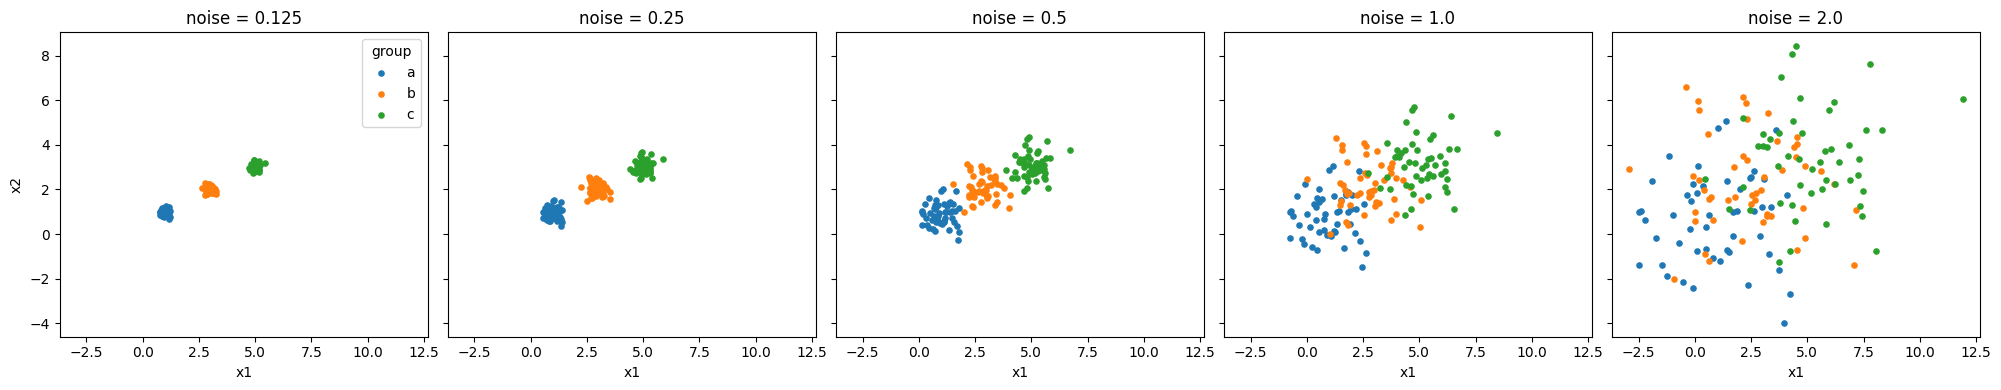

In [4]:
#Q1Part2
import matplotlib.pyplot as plt
datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}
colors = {'a': 'tab:blue', 'b': 'tab:orange', 'c': 'tab:green'}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for ax, (noise, df) in zip(axes, datasets.items()):
    for g, sub in df.groupby('group'):
        ax.scatter(sub['x1'], sub['x2'], s=14, c=colors[g], label=g)
    ax.set_title(f'noise = {noise}')
    ax.set_xlabel('x1')
axes[0].set_ylabel('x2')
axes[0].legend(title='group')
plt.tight_layout()
plt.show()

Q1Part2 Explanation

At noise 0.125 and 0.25, the three groups are tight and distinct blobs.
At 0.5, the groups are still identifiable, but the edges of the blobs begin to touch.
At 1.0, the groups overlap heavily. You can still see a left-to-right trend but the boundaries are blurry.
At 2.0, the groups are almost one cloud. The points are scattered across the plot, and the group colors are intermixed. Without the colors, you would not see three clusters.
So in general as the noise increases, the visual distinctness of the clusters decrease.

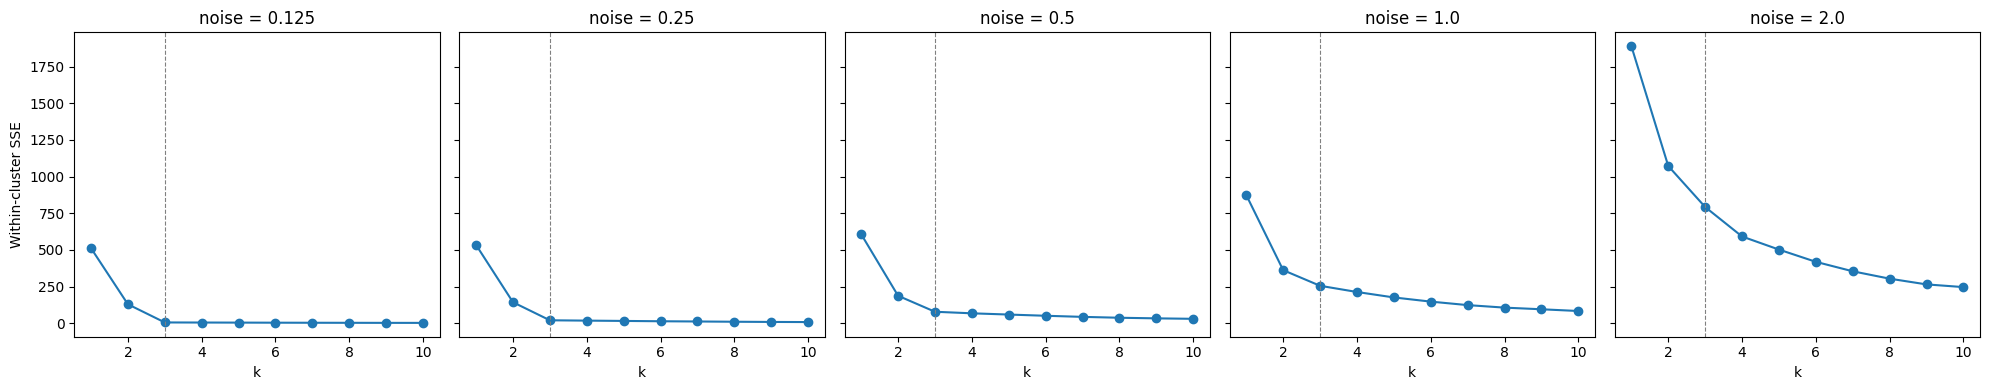

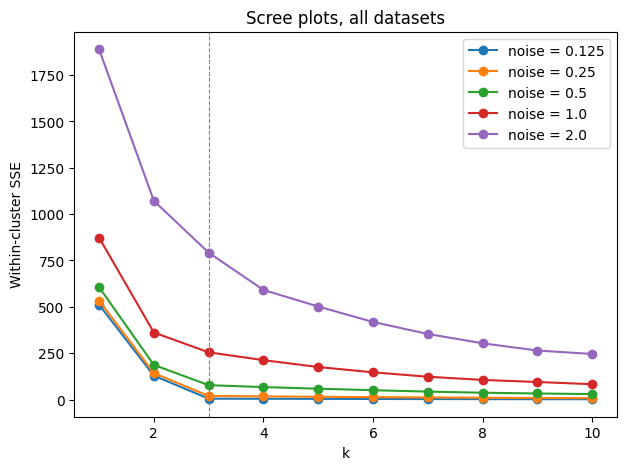

In [6]:
from sklearn.cluster import KMeans
ks = range(1, 11)
sse = {}
for noise, df in datasets.items():
    X = df[['x1', 'x2']].values
    sse[noise] = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]

# Separate panels, same vertical axis
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, (noise, vals) in zip(axes, sse.items()):
    ax.plot(list(ks), vals, 'o-')
    ax.axvline(3, color='gray', ls='--', lw=0.8)  # true k
    ax.set_title(f'noise = {noise}')
    ax.set_xlabel('k')
axes[0].set_ylabel('Within-cluster SSE')
plt.tight_layout()
plt.show()

# All curves on one canvas
plt.figure(figsize=(7, 5))
for noise, vals in sse.items():
    plt.plot(list(ks), vals, 'o-', label=f'noise = {noise}')
plt.axvline(3, color='gray', ls='--', lw=0.8)
plt.xlabel('k')
plt.ylabel('Within-cluster SSE')
plt.title('Scree plots, all datasets')
plt.legend()
plt.show()

3c. How noise affects the scree plot and the elbow

As noise increases, the elbow at k = 3 gets weaker and eventually disappears. At noise 0.125 and 0.25, the scree curve drops steeply from k = 1 to k = 3 and is nearly flat afterward, which produces a sharp and obvious elbow. At noise 0.5, the elbow is still visible but the curve after k = 3 declines more gradually. At noise 1.0, the bend at k = 3 is slight, and at noise 2.0 the curve is more smooth and a steady decline with not much of a bend. The overall height of the curve also rises with noise, because more of the variation is random scatter within each group, so adding clusters explains less of it. In general, the more noise there is the flatter and less distinct the elbow becomes.

3d. Ability to select k

At low noise (0.125 and 0.25), I can definitively pick k = 3 from the scree plot, because the elbow is unmistakable and matches the true number of groups. At noise 0.5, I can still pick k = 3 with reasonable confidence, though with less certainty. At noise 1.0, the choice is ambiguous, since k = 2, 3 or 4 could each be defended. At noise 2.0, the scree plot gives no basis for choosing k, because there is no elbow and any k from 2 to 6 looks about equally reasonable. In that case, I would need other tools, such as silhouette scores or knowledge about the data, rather than relying on the elbow alone. In general, the more noise there is the harder it is to select k from the scree plot.

4.Intuition of the elbow

The scree plot shows how much within-cluster spread is left as k increases, and it always falls because more centers put every point closer to a center. The elbow is where the big improvements stop and the gains become small. In our simulation, going from k = 1 to 3 gives large drops because each real group gets its own center, but beyond k = 3 extra clusters only split groups that were already tight, so the curve flattens. This is clear at low noise, where the groups are well separated, and it disappears at high noise, where the groups overlap and the curve declines steadily with no bend. In short, the elbow is a sign that you have found the number of clusters the structure of the data supports, and it only appears clearly when the clusters are well separated.

In [17]:
#Question2 Part 1
df = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')

# ---- 1a: filter to 2020 and drop missing values (this is the only cleaning step) ----
d = df[df['Year'] == 2020].dropna().reset_index(drop=True)
print(d.shape)                                  # 148 countries

# ---- 1b: checks showing no further cleaning is needed ----
num = ['Spending (2020 USD)', 'Spending per Capita',
       'Percent of Government Spending', 'Percent of GDP']
print(d[num].describe().T)                      # all numeric, plausible ranges
print('missing:', d.isna().sum().sum())                 # 0
print('duplicate countries:', d['Country'].duplicated().sum())   # 0
print('negative values:', (d[num] < 0).sum().sum())     # 0
print('zero values:', (d[num] == 0).sum().sum())        # 0
print(d['Country'].tolist())                    # all individual countries, no regional totals

(148, 7)
                                count          mean           std       min  \
Spending (2020 USD)             148.0  13153.747670  68005.236120  8.622460   
Spending per Capita             148.0    268.264494    430.434878  0.580129   
Percent of Government Spending  148.0      0.061510      0.046207  0.004896   
Percent of GDP                  148.0      0.019619      0.015033  0.000054   

                                       25%         50%          75%  \
Spending (2020 USD)             204.877177  959.535443  5289.998320   
Spending per Capita              20.553464   81.506703   326.267753   
Percent of Government Spending    0.031352    0.047402     0.084681   
Percent of GDP                    0.010413    0.015324     0.024327   

                                          max  
Spending (2020 USD)             778397.200000  
Spending per Capita               2520.398541  
Percent of Government Spending       0.303027  
Percent of GDP                       0.098470  

1b (cleaning).

No further cleaning is needed. After dropping missing values there are 148 countries, no duplicates, no negative or zero values, and no regional aggregates. The only issue is that the variables are on very different scales (spending in the hundreds of thousands, the percent columns as fractions between 0 and 1), which is what normalization handles.

In [18]:
# 2a and 3a max-min normalization
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

for c in num:
    d[c + ' (norm)'] = minmax(d[c])

norm = [c + ' (norm)' for c in num]
print(d[norm].describe().loc[['min', 'max']])   # every column now runs from 0 to 1

     Spending (2020 USD) (norm)  Spending per Capita (norm)  \
min                         0.0                         0.0   
max                         1.0                         1.0   

     Percent of Government Spending (norm)  Percent of GDP (norm)  
min                                    0.0                    0.0  
max                                    1.0                    1.0  


In [19]:
# helper functions
def scree(cols, kmax=10):
    X = d[[c + ' (norm)' for c in cols]]
    sse = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_
           for k in range(1, kmax + 1)]
    plt.figure(figsize=(6, 4))
    plt.plot(range(1, kmax + 1), sse, 'o-')
    plt.xlabel('k'); plt.ylabel('Within-cluster SSE')
    plt.title('Scree plot: ' + ', '.join(cols))
    plt.show()
    print('drop in SSE from k to k+1:', np.round(-np.diff(sse), 3))

def cluster(cols, k, label):
    X = d[[c + ' (norm)' for c in cols]]
    d[label] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
    display(d.groupby(label)[cols].describe().T)          # describe table by cluster
    for c in range(k):
        print(c, d.loc[d[label] == c, 'Country'].tolist())
    print('United States cluster:', d.loc[d['Country'].str.startswith('United States'), label].values)

def scatter(cols, label):
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=d, x=cols[0], y=cols[1], hue=label, palette='tab10')
    us = d[d['Country'].str.startswith('United States')].iloc[0]
    plt.annotate('United States', (us[cols[0]], us[cols[1]]), xytext=(10, 10), textcoords='offset points')
    plt.title('Clusters: ' + ' vs '.join(cols))
    plt.show()

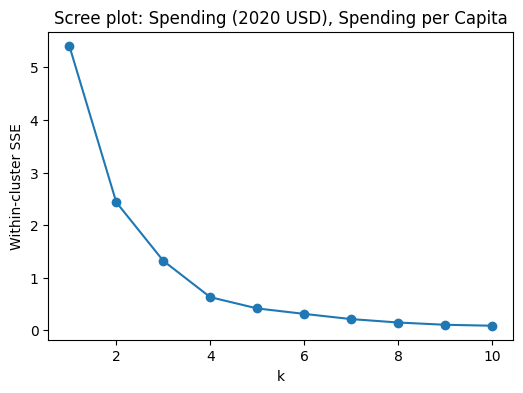

drop in SSE from k to k+1: [2.976 1.113 0.692 0.214 0.104 0.099 0.065 0.043 0.018]


c2                                    0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.880549   
                    50%      579.004604   1665.447478      47.056944   
                    75%      757.328513   1817.219993     125.387558   
                    max     1070.623322   2520.398541     314.201312   

c2                                     3  
Spending (2020 USD) count       1.000000  
                    mean   778397.200000  
                    std              NaN  
                    min    778397.200000  
                    25%    778397.200000  
                    50%    778397.200000  
                    75%    778397.200000  
                    max    778397.200000  
Spending per Capita count       1.000000  
                    mean     2351.631858  
                    std              NaN  
                    min      2351.631858  
                    25%      2351.631858  
                    50%      2351.631858  
                    75%      2351.631858  
                    max      2351.631858

0 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Italy', 'Japan', 'Korea, South', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'Slovakia', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'United Kingdom']
1 ['Israel', 'Kuwait', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore']
2 ['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Gambia, The', 'Georgia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 

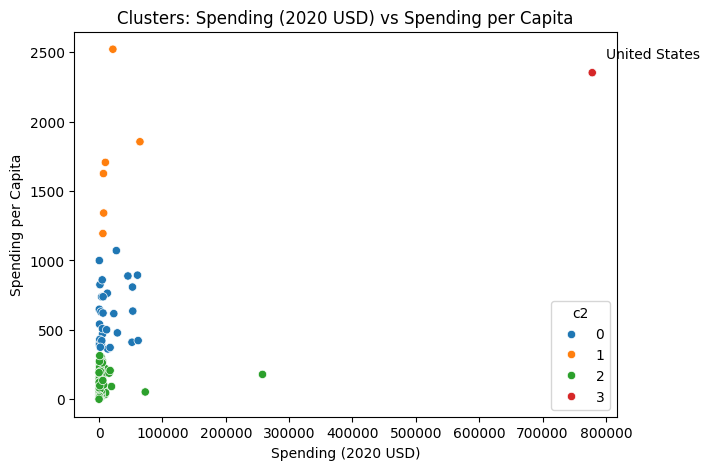

In [20]:
# Rubric 2b, 2c, 2d
import seaborn as sns
from sklearn.cluster import KMeans
cols2 = ['Spending (2020 USD)', 'Spending per Capita']
scree(cols2)                  # 2b scree plot
cluster(cols2, 4, 'c2')       # 2d describe table
scatter(cols2, 'c2')          # 2c scatter plot

2e:

The scree plot bends at k = 4, so I used four clusters. The clusters are separated mainly by how much a country spends in total and per person. One cluster has 111 countries with low spending and low per-capita spending (mean per capita about 80). A second has 30 mostly wealthy countries with moderate per-capita spending (about 607). A third has just 6 countries (Israel, Kuwait, Norway, Oman, Saudi Arabia and Singapore) with high per-capita spending (about 1,707) but only moderate totals. The fourth is the United States alone.

Where the U.S. is: The United States is in a cluster by itself, because its spending (about 778,000) and its per-capita spending (about 2,352) are far above every other country.

Patterns: The clusters follow wealth and size. Wealthy European and allied countries (UK, Germany, France, Japan, Korea, Australia, Canada) are together in the middle cluster. Small, rich or Gulf states form the high per-capita cluster. The large low-cluster group includes countries like China and India, which have big totals but low per-capita spending because their populations are so large.

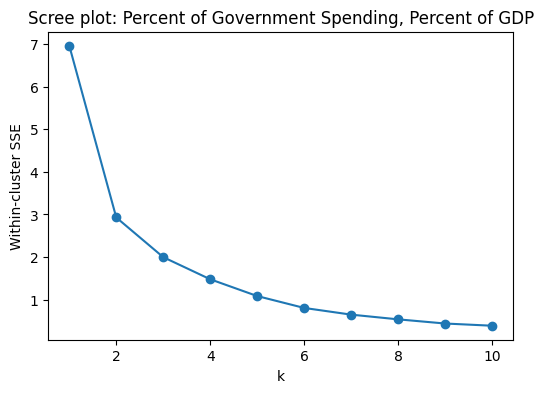

drop in SSE from k to k+1: [4.034 0.932 0.519 0.394 0.279 0.157 0.111 0.098 0.052]


c3                                            0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                               50%     0.027781   0.053729   0.013191
                               75%     0.032461   0.066190   0.016752
                               max     0.042810   0.098470   0.028132

0 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
1 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']
2 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Cameroon', 'Canada', 'Cape Verde', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gambia, The', 'Georgia', 'Germany', 'Gh

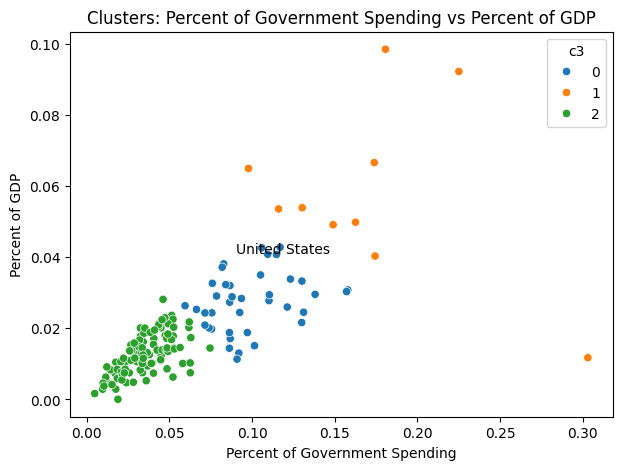

In [21]:
# Rubric 3b, 3c, 3d
cols3 = ['Percent of Government Spending', 'Percent of GDP']
scree(cols3)                  # 3b scree plot
cluster(cols3, 3, 'c3')       # 3d describe table; 3e short answers
scatter(cols3, 'c3')          # 3c scatter plot

3e. Percent of government spending and percent of GDP (k = 3)

The clusters line up by how large a share of the economy and government budget goes to the military. One cluster has 99 countries with a low share (about 3.6% of government spending and 1.3% of GDP). A second has 39 countries with a moderate share (about 9.9% and 2.7%). A third has 10 countries with a very high share (about 17% and 5.8%): Saudi Arabia, Oman, Kuwait, Israel, Pakistan, Algeria, Armenia, Azerbaijan, Jordan and Belarus.

Where the U.S. is: The United States is in the moderate-share cluster, along with Russia, India, Iran, Korea and Taiwan. It is not unusual here, because its military is large in absolute terms but is a modest share of its huge economy and budget.

Patterns: The high-share cluster is concentrated in the Middle East and in countries with regional tensions or conflicts. The low-share cluster includes most of Western Europe, China, Japan, Canada and many countries in Latin America and Africa.

3f. Comparison to part 2

Part 2 groups countries by the size of their spending, and the U.S. stands out alone. Part 3 groups them by how much of their economy and budget goes to the military, and the U.S. looks ordinary (moderate). Countries like China and Japan, which are big spenders in total, land in the low-share group here. Gulf states and Israel stand out in both parts, which shows that they spend a lot both in absolute terms per person and as a share of their economies.

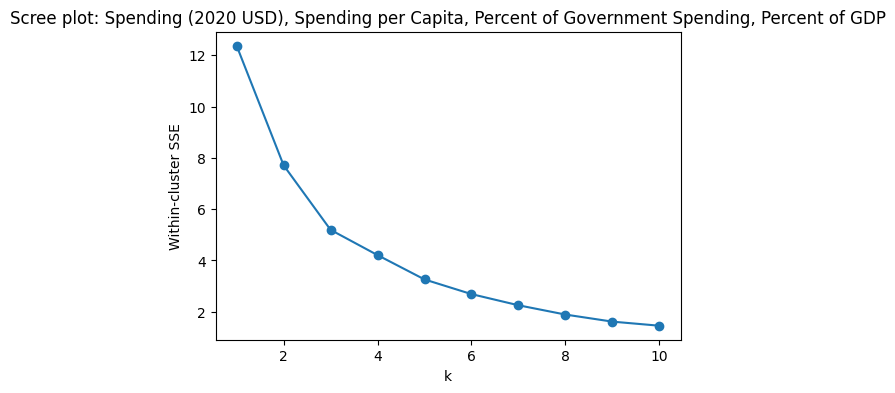

drop in SSE from k to k+1: [4.662 2.518 0.986 0.949 0.572 0.435 0.362 0.276 0.159]


c4                                                0             1  \
Spending (2020 USD)            count     111.000000     31.000000   
                               mean     7086.472777   8786.086602   
                               std     26479.379918  17901.909108   
                               min         8.622460    162.373364   
                               25%       130.010211    467.787851   
                               50%       567.650747   1404.787234   
                               75%      3910.107493   7739.166193   
                               max    257973.429834  72937.064048   
Spending per Capita            count     111.000000     31.000000   
                               mean      196.926833    212.689100   
                               std       267.788506    257.841988   
                               min         0.580129     18.297119   
                               25%        14.880549     46.485917   
                               50%        67.083417    135.459845   
                               75%       295.296094    217.333791   
                               max      1341.058851    998.966186   
Percent of Government Spending count     111.000000     31.000000   
                               mean        0.040350      0.122985   
                               std         0.019320      0.043927   
                               min         0.004896      0.076005   
                               25%         0.026712      0.093093   
                               50%         0.037952      0.114776   
                               75%         0.050505      0.134663   
                               max         0.092044      0.303027   
Percent of GDP                 count     111.000000     31.000000   
                               mean        0.013419      0.033492   
                               std         0.005996      0.011449   
                               min         0.000054      0.011742   
                               25%         0.008873      0.027560   
                               50%         0.013589      0.032024   
                               75%         0.017769      0.040531   
                               max         0.028132      0.066600   

c4                                                2  
Spending (2020 USD)            count       6.000000  
                               mean   147964.582042  
                               std    309635.189564  
                               min      6095.708713  
                               25%      7700.424616  
                               50%     15897.570598  
                               75%     53872.942442  
                               max    778397.200000  
Spending per Capita            count       6.000000  
                               mean     1875.150751  
                               std       489.800206  
                               min      1193.598730  
                               25%      1645.301864  
                               50%      1780.059564  
                               75%      2227.318999  
                               max      2520.398541  
Percent of Government Spending count       6.000000  
                               mean        0.135351  
                               std         0.055392  
                               min         0.081976  
                               25%         0.101034  
                               50%         0.113271  
                               75%         0.164503  
                               max         0.225050  
Percent of GDP                 count       6.000000  
                               mean        0.062634  
                               std         0.028275  
                               min         0.029429  
                               25%         0.041272  
                               50%         0.059257  
                               75%         0.085

0 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Bangladesh', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Latvia', 'Lesotho', 'Liberia', 'Lithuania', 'Luxembourg', 'Madagascar', 'Malawi', 'Malaysia', 'Malta', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Mozambique', 'Nepal', 'Netherlands', 'New Zealand', 'Nicaragua', 'Niger', 'Nigeria', 'North Macedonia', 'Norway', 'Papua New Guinea', 'Paraguay', 

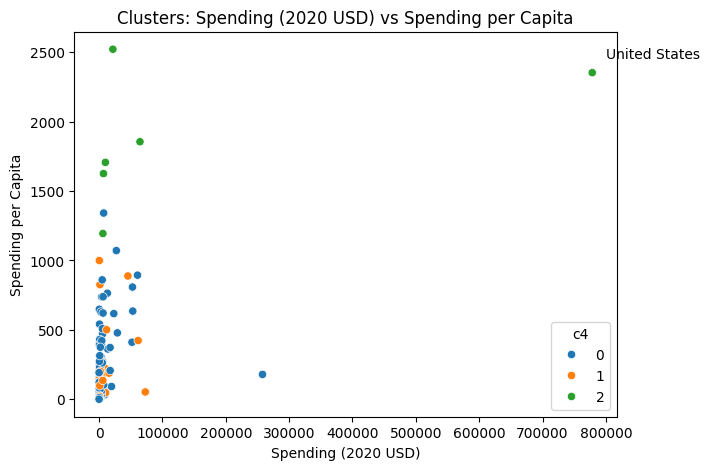

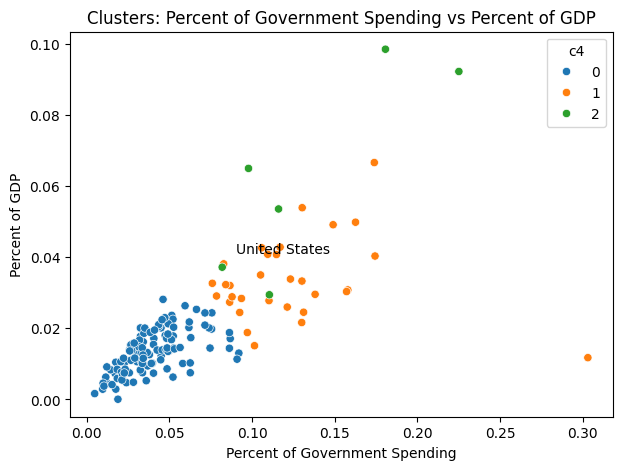

In [22]:
# Rubric 4a, 4b
scree(num)                    # supports the choice of k for part 4
cluster(num, 3, 'c4')         # 4a/4b: k means on all four variables, describe table shows all four
scatter(cols2, 'c4')          # extra visual, not required by the rubric
scatter(cols3, 'c4')          # extra visual, not required by the rubric

4c. Comparison of the four-variable results to parts 2 and 3 (k = 3)

Using all four variables, three clusters appeared. The first has 6 countries (U.S., Saudi Arabia, Israel, Singapore, Kuwait, Oman) that are high on every variable. The second has 31 countries (India, Russia, Korea, Iran, Pakistan, Ukraine and others) with a high spending share (about 12% of government spending) but low per-capita spending (about 213). The third has 111 countries with a low spending share, including China and most of Western Europe. Compared to part 2, the U.S. is no longer alone and is grouped with the Gulf states and Israel. Compared to part 3, the high-share group is split into countries that also spend a lot per person and countries that do not. At k = 3, wealthy European allies are not separated from the low-share group, because the share variables pull them into it. They do split off at k = 4.

5.Usefulness of patterns found by the k-MC algorithm

Yes, the clustering found useful patterns, with some limits. It showed that “military spending” is really several different things: how much a country spends in total, how much it spends per person, and how much of its economy and budget it devotes to the military. The four-variable clustering was the most informative, because it found groups that neither pair of variables showed alone, such as the small set of countries that are high on everything, and the group with a high spending share but modest absolute spending. The limits are that the elbows were not sharp (especially in part 3), so the choice of k is subjective. The U.S. and China are extreme values that dominate the max-min scaling, which can hide differences among the other countries. The clusters also describe patterns without explaining why countries spend what they do, so they are mainly a starting point for further analysis.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 44794f97308d029f540f561043600b9b3a4d8fc4
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Here is my phase 1 solution: (attatched phase 1 ipynb). Are there any ways in which you would optimize the current solution or do you see any error that need to be corrected?
2. From the following suggestions you gave me, rank them in order of importance/severity.

### *AI-proposed changes




1. Show both a raw and a rescaled scree plot in Q1. Plot each curve divided by its k = 1 value, next to the raw shared-axis plot. On the raw plot the noisy curves look dramatic only because their SSE is larger. Rescaling lets you judge the shape of the elbow, which is what 3c and 3d ask about.
2. Add silhouette scores next to each scree plot in Q2. This gives a second check on k. The result is worth reporting honestly: silhouette favors k = 2 in all three parts (raw data: part 2 scores 0.759 at k = 2 vs 0.701 at k = 4; part 3, 0.616 vs 0.539 at k = 3; part 4, 0.577 vs 0.480 at k = 3). So the scree-based k values (4, 3, 3) are judgment calls, and your write-up should say so.
3. 4c says the 6-country cluster is “high on every variable.” That is wrong for total spending: only the US is far above the rest, and the others range from about 6,100 to 61,000. Say instead that they have high per-capita spending and a high spending share, with the US also far ahead in total.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Reason: The raw plot makes noisy curves look dramatic only because their SSE is larger, and the rescaled one lets you judge the shape of the elbow. Verification: I plotted SSE at k = 3 as a fraction of SSE at k = 1, and it rises steadily with noise: 0.010, 0.037, 0.128, 0.292, 0.419 for noise 0.125 to 2.0. That matches the elbow disappearing.|
| 2 | Accept | Reason: The scree plots in Q2 have unclear elbows (especially part 3), so a second criterion shows how much the choice of k depends on judgment. Verification: I computed average silhouette scores for k = 2 to 8. They are highest at k = 2 in all three parts: part 2 is 0.759 (k = 2) vs 0.701 (k = 4); part 3 is 0.616 (k = 2) vs 0.539 (k = 3); part 4 is 0.577 (k = 2) vs 0.480 (k = 3). |
| 3 | Accept | Reason: The cluster mean for total spending is driven by the US, so “high on every variable” overstates it for the other five countries.Verification: Total spending is 6,100 to 64,600, above the typical country (median 960) but far below the US at 778,397. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [1]:
# Your Phase 2 solution to the problem goes here.
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

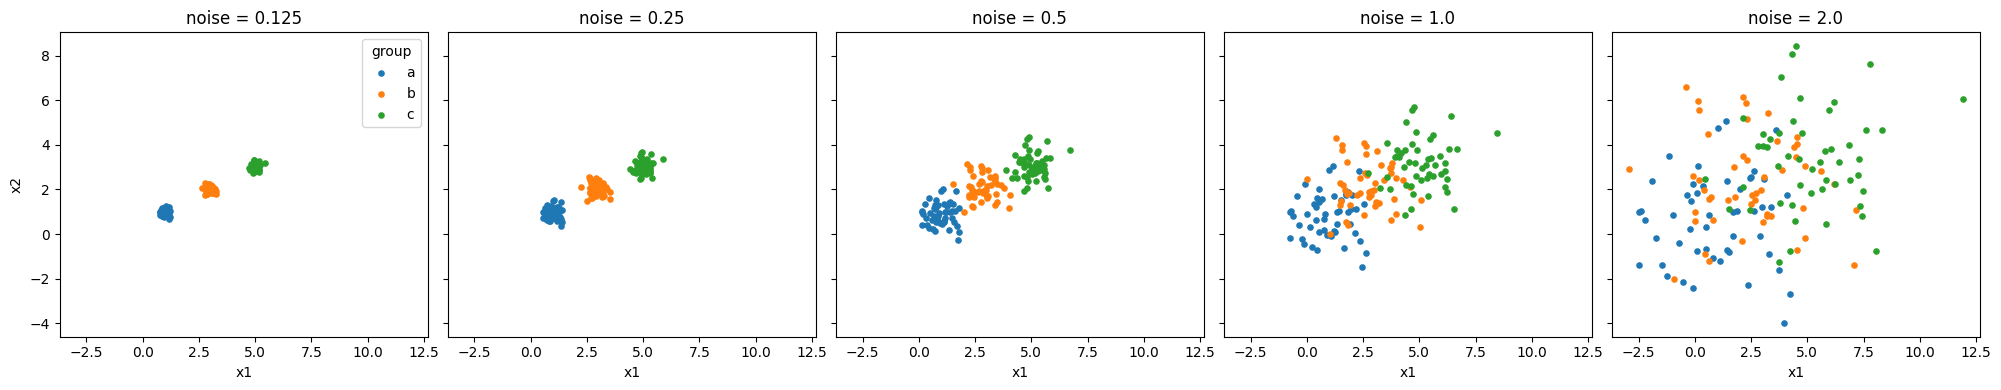

In [2]:
#Q1Part2
import matplotlib.pyplot as plt
datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}
colors = {'a': 'tab:blue', 'b': 'tab:orange', 'c': 'tab:green'}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for ax, (noise, df) in zip(axes, datasets.items()):
    for g, sub in df.groupby('group'):
        ax.scatter(sub['x1'], sub['x2'], s=14, c=colors[g], label=g)
    ax.set_title(f'noise = {noise}')
    ax.set_xlabel('x1')
axes[0].set_ylabel('x2')
axes[0].legend(title='group')
plt.tight_layout()
plt.show()

Q1Part2 Explanation

At noise 0.125 and 0.25, the three groups are tight and distinct blobs. At 0.5, the groups are still identifiable, but the edges of the blobs begin to touch. At 1.0, the groups overlap heavily. You can still see a left-to-right trend but the boundaries are blurry. At 2.0, the groups are almost one cloud. The points are scattered across the plot, and the group colors are intermixed. Without the colors, you would not see three clusters. So in general as the noise increases, the visual distinctness of the clusters decrease.

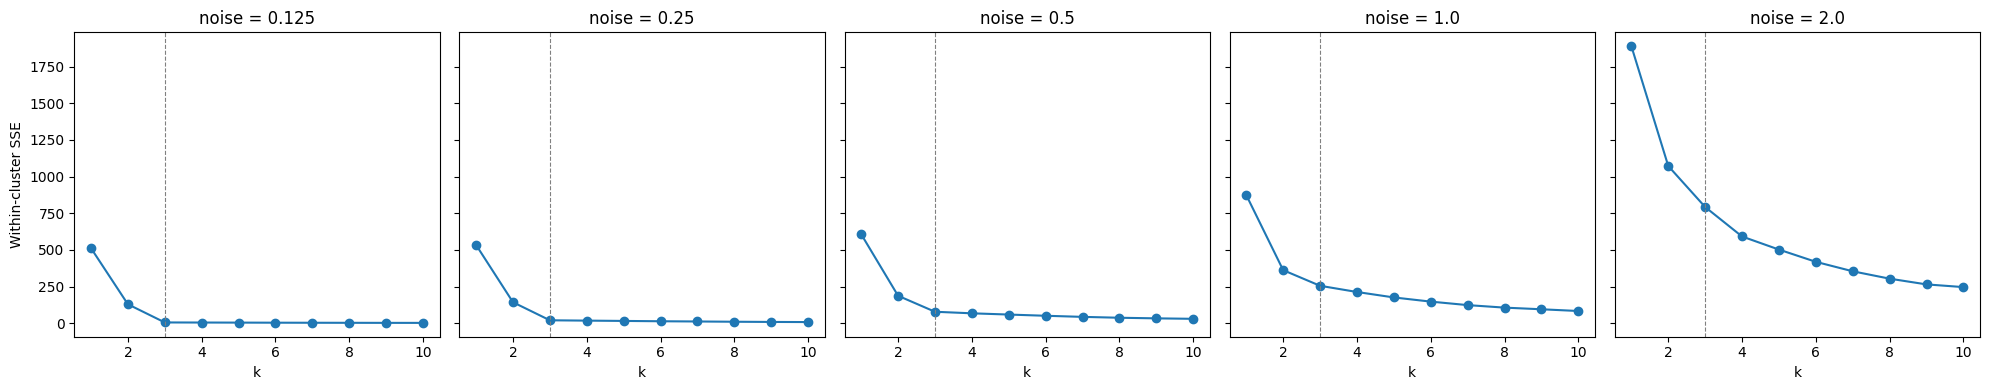

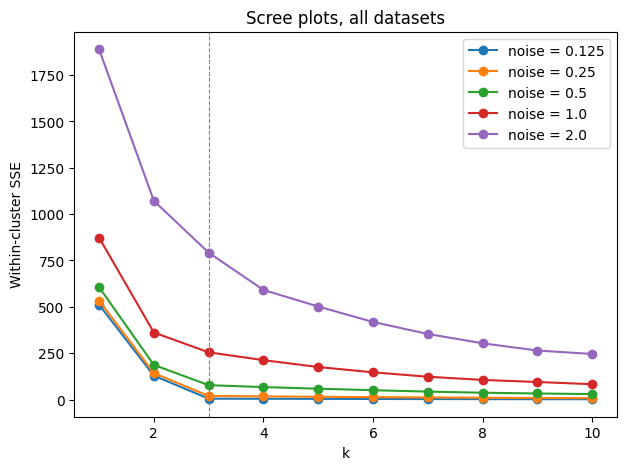

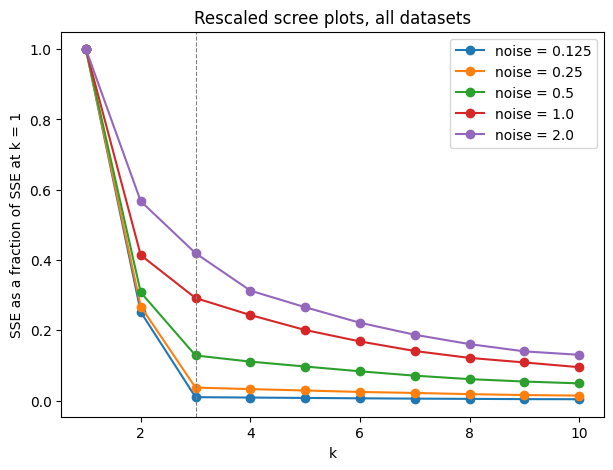

In [3]:
from sklearn.cluster import KMeans
ks = range(1, 11)
sse = {}
for noise, df in datasets.items():
    X = df[['x1', 'x2']].values
    sse[noise] = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]

# Separate panels, same vertical axis
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, (noise, vals) in zip(axes, sse.items()):
    ax.plot(list(ks), vals, 'o-')
    ax.axvline(3, color='gray', ls='--', lw=0.8)  # true k
    ax.set_title(f'noise = {noise}')
    ax.set_xlabel('k')
axes[0].set_ylabel('Within-cluster SSE')
plt.tight_layout()
plt.show()

# All curves on one canvas
plt.figure(figsize=(7, 5))
for noise, vals in sse.items():
    plt.plot(list(ks), vals, 'o-', label=f'noise = {noise}')
plt.axvline(3, color='gray', ls='--', lw=0.8)
plt.xlabel('k')
plt.ylabel('Within-cluster SSE')
plt.title('Scree plots, all datasets')
plt.legend()
plt.show()

# NEW AI PROPOSED CHANGE: Rescaled scree plot: each curve divided by its own SSE at k = 1
plt.figure(figsize=(7, 5))
for noise, vals in sse.items():
    plt.plot(list(ks), np.array(vals) / vals[0], 'o-', label=f'noise = {noise}')
plt.axvline(3, color='gray', ls='--', lw=0.8)
plt.xlabel('k')
plt.ylabel('SSE as a fraction of SSE at k = 1')
plt.title('Rescaled scree plots, all datasets')
plt.legend()
plt.show()

3c. How noise affects the scree plot and the elbow

As noise increases, the elbow at k = 3 gets weaker and eventually disappears. At noise 0.125 and 0.25, the scree curve drops steeply from k = 1 to k = 3 and is nearly flat afterward, which produces a sharp and obvious elbow. At noise 0.5, the elbow is still visible but the curve after k = 3 declines more gradually. At noise 1.0, the bend at k = 3 is slight, and at noise 2.0 the curve is more smooth and a steady decline with not much of a bend. The overall height of the curve also rises with noise, because more of the variation is random scatter within each group, so adding clusters explains less of it. In general, the more noise there is the flatter and less distinct the elbow becomes.

3d. Ability to select k

At low noise (0.125 and 0.25), I can definitively pick k = 3 from the scree plot, because the elbow is unmistakable and matches the true number of groups. At noise 0.5, I can still pick k = 3 with reasonable confidence, though with less certainty. At noise 1.0, the choice is ambiguous, since k = 2, 3 or 4 could each be defended. At noise 2.0, the scree plot gives no basis for choosing k, because there is no elbow and any k from 2 to 6 looks about equally reasonable. In that case, I would need other tools, such as silhouette scores or knowledge about the data, rather than relying on the elbow alone. In general, the more noise there is the harder it is to select k from the scree plot.

4.Intuition of the elbow

The scree plot shows how much within-cluster spread is left as k increases, and it always falls because more centers put every point closer to a center. The elbow is where the big improvements stop and the gains become small. In our simulation, going from k = 1 to 3 gives large drops because each real group gets its own center, but beyond k = 3 extra clusters only split groups that were already tight, so the curve flattens. This is clear at low noise, where the groups are well separated, and it disappears at high noise, where the groups overlap and the curve declines steadily with no bend. In short, the elbow is a sign that you have found the number of clusters the structure of the data supports, and it only appears clearly when the clusters are well separated.

In [4]:
#Question2 Part 1
df = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')

# ---- 1a: filter to 2020 and drop missing values (this is the only cleaning step) ----
d = df[df['Year'] == 2020].dropna().reset_index(drop=True)
print(d.shape)                                  # 148 countries

# ---- 1b: checks showing no further cleaning is needed ----
num = ['Spending (2020 USD)', 'Spending per Capita',
       'Percent of Government Spending', 'Percent of GDP']
print(d[num].describe().T)                      # all numeric, plausible ranges
print('missing:', d.isna().sum().sum())                 # 0
print('duplicate countries:', d['Country'].duplicated().sum())   # 0
print('negative values:', (d[num] < 0).sum().sum())     # 0
print('zero values:', (d[num] == 0).sum().sum())        # 0
print(d['Country'].tolist())                    # all individual countries, no regional totals

(148, 7)
                                count          mean           std       min  \
Spending (2020 USD)             148.0  13153.747670  68005.236120  8.622460   
Spending per Capita             148.0    268.264494    430.434878  0.580129   
Percent of Government Spending  148.0      0.061510      0.046207  0.004896   
Percent of GDP                  148.0      0.019619      0.015033  0.000054   

                                       25%         50%          75%  \
Spending (2020 USD)             204.877177  959.535443  5289.998320   
Spending per Capita              20.553464   81.506703   326.267753   
Percent of Government Spending    0.031352    0.047402     0.084681   
Percent of GDP                    0.010413    0.015324     0.024327   

                                          max  
Spending (2020 USD)             778397.200000  
Spending per Capita               2520.398541  
Percent of Government Spending       0.303027  
Percent of GDP                       0.098470  

1b (cleaning).

No further cleaning is needed. After dropping missing values there are 148 countries, no duplicates, no negative or zero values, and no regional aggregates. The only issue is that the variables are on very different scales (spending in the hundreds of thousands, the percent columns as fractions between 0 and 1), which is what normalization handles.

In [5]:
# 2a and 3a max-min normalization
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

for c in num:
    d[c + ' (norm)'] = minmax(d[c])

norm = [c + ' (norm)' for c in num]
print(d[norm].describe().loc[['min', 'max']])   # every column now runs from 0 to 1

     Spending (2020 USD) (norm)  Spending per Capita (norm)  \
min                         0.0                         0.0   
max                         1.0                         1.0   

     Percent of Government Spending (norm)  Percent of GDP (norm)  
min                                    0.0                    0.0  
max                                    1.0                    1.0  


In [8]:
#helper functions
def scree(cols, kmax=10):
    X = d[[c + ' (norm)' for c in cols]]
    sse = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_
           for k in range(1, kmax + 1)]
    plt.figure(figsize=(6, 4))
    plt.plot(range(1, kmax + 1), sse, 'o-')
    plt.xlabel('k'); plt.ylabel('Within-cluster SSE')
    plt.title('Scree plot: ' + ', '.join(cols))
    plt.show()
    print('drop in SSE from k to k+1:', np.round(-np.diff(sse), 3))

# ---- CHANGE 2 (new): silhouette helper ----
def silhouette(cols, kmax=8):
    from sklearn.metrics import silhouette_score   # import here so it always runs
    X = d[[c + ' (norm)' for c in cols]]
    ksil = list(range(2, kmax + 1))
    sil = [silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)) for k in ksil]
    plt.figure(figsize=(6, 4))
    plt.plot(ksil, sil, 'o-')
    plt.xlabel('k'); plt.ylabel('Average silhouette score')
    plt.title('Silhouette: ' + ', '.join(cols))
    plt.show()
    print('best k by silhouette:', ksil[int(np.argmax(sil))])

def cluster(cols, k, label):
    X = d[[c + ' (norm)' for c in cols]]
    d[label] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
    display(d.groupby(label)[cols].describe().T)          # describe table by cluster
    for c in range(k):
        print(c, d.loc[d[label] == c, 'Country'].tolist())
    print('United States cluster:', d.loc[d['Country'].str.startswith('United States'), label].values)

def scatter(cols, label):
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=d, x=cols[0], y=cols[1], hue=label, palette='tab10')
    us = d[d['Country'].str.startswith('United States')].iloc[0]
    plt.annotate('United States', (us[cols[0]], us[cols[1]]), xytext=(10, 10), textcoords='offset points')
    plt.title('Clusters: ' + ' vs '.join(cols))
    plt.show()

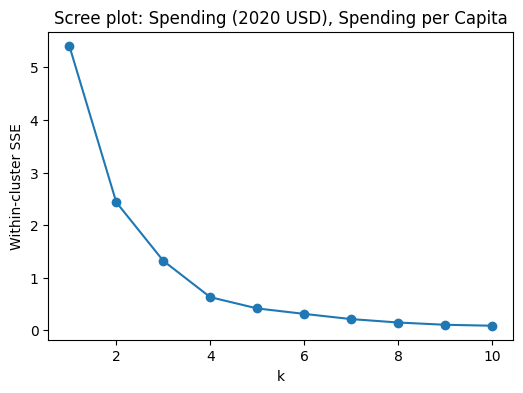

drop in SSE from k to k+1: [2.976 1.113 0.692 0.214 0.104 0.099 0.065 0.043 0.018]


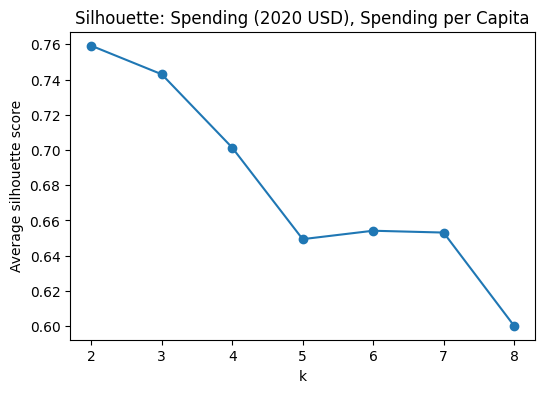

best k by silhouette: 2


c2                                    0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.880549   
                    50%      579.004604   1665.447478      47.056944   
                    75%      757.328513   1817.219993     125.387558   
                    max     1070.623322   2520.398541     314.201312   

c2                                     3  
Spending (2020 USD) count       1.000000  
                    mean   778397.200000  
                    std              NaN  
                    min    778397.200000  
                    25%    778397.200000  
                    50%    778397.200000  
                    75%    778397.200000  
                    max    778397.200000  
Spending per Capita count       1.000000  
                    mean     2351.631858  
                    std              NaN  
                    min      2351.631858  
                    25%      2351.631858  
                    50%      2351.631858  
                    75%      2351.631858  
                    max      2351.631858

0 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Italy', 'Japan', 'Korea, South', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'Slovakia', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'United Kingdom']
1 ['Israel', 'Kuwait', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore']
2 ['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Gambia, The', 'Georgia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 

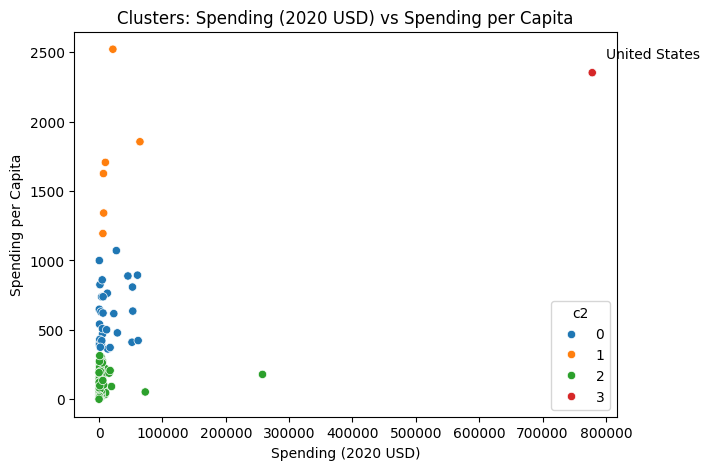

In [9]:
# Rubric 2b, 2c, 2d
import seaborn as sns
from sklearn.cluster import KMeans
cols2 = ['Spending (2020 USD)', 'Spending per Capita']
scree(cols2)                  # 2b scree plot
silhouette(cols2)             # CHANGE 2
cluster(cols2, 4, 'c2')       # 2d describe table
scatter(cols2, 'c2')          # 2c scatter plot

2e:

The scree plot bends at k = 4, so I used four clusters. The clusters are separated mainly by how much a country spends in total and per person. One cluster has 111 countries with low spending and low per-capita spending (mean per capita about 80). A second has 30 mostly wealthy countries with moderate per-capita spending (about 607). A third has just 6 countries (Israel, Kuwait, Norway, Oman, Saudi Arabia and Singapore) with high per-capita spending (about 1,707) but only moderate totals. The fourth is the United States alone.

Where the U.S. is: The United States is in a cluster by itself, because its spending (about 778,000) and its per-capita spending (about 2,352) are far above every other country.

Patterns: The clusters follow wealth and size. Wealthy European and allied countries (UK, Germany, France, Japan, Korea, Australia, Canada) are together in the middle cluster. Small, rich or Gulf states form the high per-capita cluster. The large low-cluster group includes countries like China and India, which have big totals but low per-capita spending because their populations are so large.

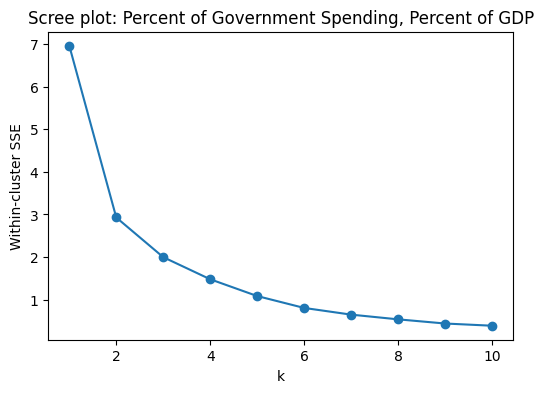

drop in SSE from k to k+1: [4.034 0.932 0.519 0.394 0.279 0.157 0.111 0.098 0.052]


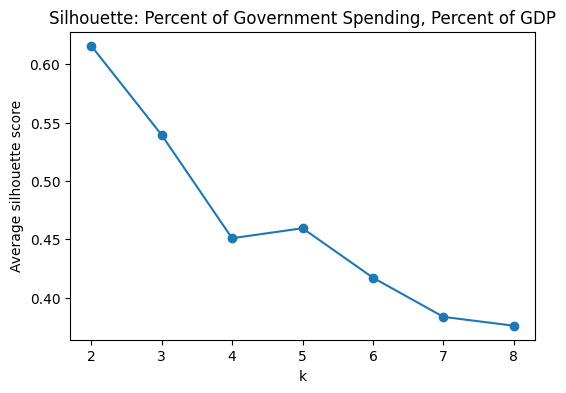

best k by silhouette: 2


c3                                            0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                               50%     0.027781   0.053729   0.013191
                               75%     0.032461   0.066190   0.016752
                               max     0.042810   0.098470   0.028132

0 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
1 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']
2 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Cameroon', 'Canada', 'Cape Verde', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gambia, The', 'Georgia', 'Germany', 'Gh

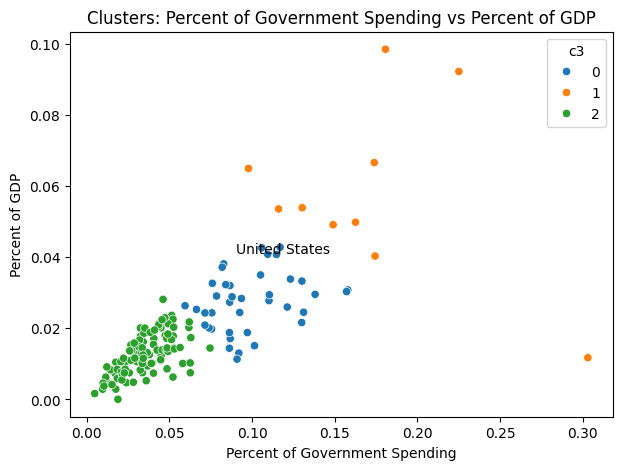

In [10]:
# Rubric 3b, 3c, 3d
cols3 = ['Percent of Government Spending', 'Percent of GDP']
scree(cols3)                  # 3b scree plot
silhouette(cols3)             # CHANGE 2
cluster(cols3, 3, 'c3')       # 3d describe table; 3e short answers
scatter(cols3, 'c3')          # 3c scatter plot

3e. Percent of government spending and percent of GDP (k = 3)

The clusters line up by how large a share of the economy and government budget goes to the military. One cluster has 99 countries with a low share (about 3.6% of government spending and 1.3% of GDP). A second has 39 countries with a moderate share (about 9.9% and 2.7%). A third has 10 countries with a very high share (about 17% and 5.8%): Saudi Arabia, Oman, Kuwait, Israel, Pakistan, Algeria, Armenia, Azerbaijan, Jordan and Belarus.

Where the U.S. is: The United States is in the moderate-share cluster, along with Russia, India, Iran, Korea and Taiwan. It is not unusual here, because its military is large in absolute terms but is a modest share of its huge economy and budget.

Patterns: The high-share cluster is concentrated in the Middle East and in countries with regional tensions or conflicts. The low-share cluster includes most of Western Europe, China, Japan, Canada and many countries in Latin America and Africa.

3f. Comparison to part 2

Part 2 groups countries by the size of their spending, and the U.S. stands out alone. Part 3 groups them by how much of their economy and budget goes to the military, and the U.S. looks ordinary (moderate). Countries like China and Japan, which are big spenders in total, land in the low-share group here. Gulf states and Israel stand out in both parts, which shows that they spend a lot both in absolute terms per person and as a share of their economies.

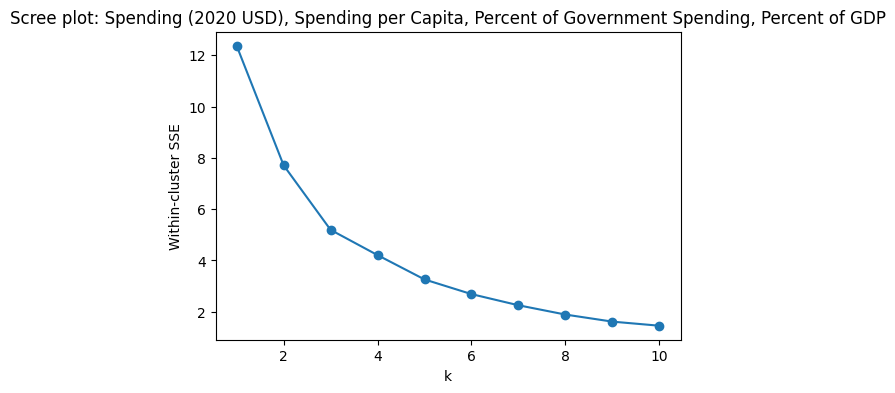

drop in SSE from k to k+1: [4.662 2.518 0.986 0.949 0.572 0.435 0.362 0.276 0.159]


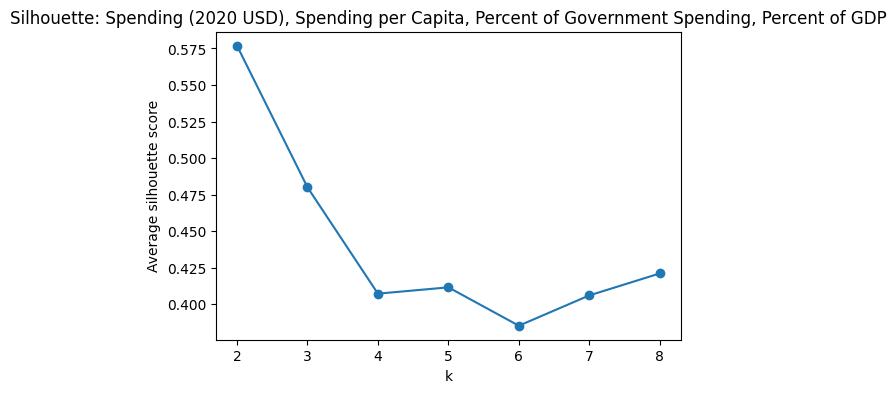

best k by silhouette: 2


c4                                                0             1  \
Spending (2020 USD)            count     111.000000     31.000000   
                               mean     7086.472777   8786.086602   
                               std     26479.379918  17901.909108   
                               min         8.622460    162.373364   
                               25%       130.010211    467.787851   
                               50%       567.650747   1404.787234   
                               75%      3910.107493   7739.166193   
                               max    257973.429834  72937.064048   
Spending per Capita            count     111.000000     31.000000   
                               mean      196.926833    212.689100   
                               std       267.788506    257.841988   
                               min         0.580129     18.297119   
                               25%        14.880549     46.485917   
                               50%        67.083417    135.459845   
                               75%       295.296094    217.333791   
                               max      1341.058851    998.966186   
Percent of Government Spending count     111.000000     31.000000   
                               mean        0.040350      0.122985   
                               std         0.019320      0.043927   
                               min         0.004896      0.076005   
                               25%         0.026712      0.093093   
                               50%         0.037952      0.114776   
                               75%         0.050505      0.134663   
                               max         0.092044      0.303027   
Percent of GDP                 count     111.000000     31.000000   
                               mean        0.013419      0.033492   
                               std         0.005996      0.011449   
                               min         0.000054      0.011742   
                               25%         0.008873      0.027560   
                               50%         0.013589      0.032024   
                               75%         0.017769      0.040531   
                               max         0.028132      0.066600   

c4                                                2  
Spending (2020 USD)            count       6.000000  
                               mean   147964.582042  
                               std    309635.189564  
                               min      6095.708713  
                               25%      7700.424616  
                               50%     15897.570598  
                               75%     53872.942442  
                               max    778397.200000  
Spending per Capita            count       6.000000  
                               mean     1875.150751  
                               std       489.800206  
                               min      1193.598730  
                               25%      1645.301864  
                               50%      1780.059564  
                               75%      2227.318999  
                               max      2520.398541  
Percent of Government Spending count       6.000000  
                               mean        0.135351  
                               std         0.055392  
                               min         0.081976  
                               25%         0.101034  
                               50%         0.113271  
                               75%         0.164503  
                               max         0.225050  
Percent of GDP                 count       6.000000  
                               mean        0.062634  
                               std         0.028275  
                               min         0.029429  
                               25%         0.041272  
                               50%         0.059257  
                               75%         0.085

0 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Bangladesh', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Latvia', 'Lesotho', 'Liberia', 'Lithuania', 'Luxembourg', 'Madagascar', 'Malawi', 'Malaysia', 'Malta', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Mozambique', 'Nepal', 'Netherlands', 'New Zealand', 'Nicaragua', 'Niger', 'Nigeria', 'North Macedonia', 'Norway', 'Papua New Guinea', 'Paraguay', 

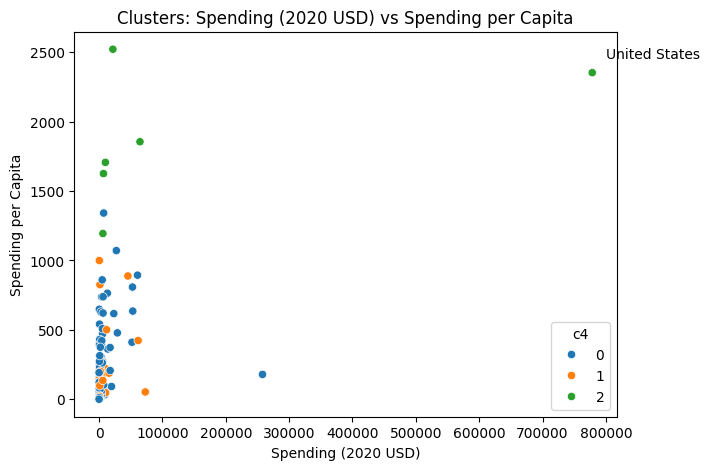

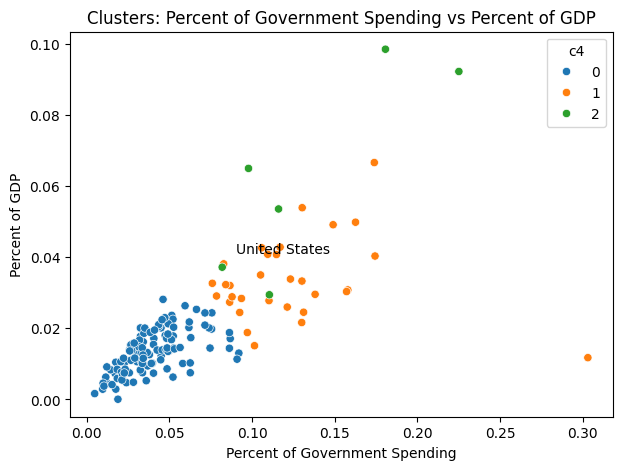

In [11]:
# Rubric 4a, 4b
scree(num)                    # supports the choice of k for part 4
silhouette(num)               # CHANGE 2
cluster(num, 3, 'c4')         # 4a/4b: k means on all four variables, describe table shows all four
scatter(cols2, 'c4')          # extra visual, not required by the rubric
scatter(cols3, 'c4')          # extra visual, not required by the rubric

4c. NEW AI PROPOSED CHANGE: Comparison of the four-variable results to parts 2 and 3 (k = 3)

Using all four variables, three clusters appeared. The first has 6 countries (U.S., Saudi Arabia, Israel, Singapore, Kuwait, Oman) with high per-capita spending and a high spending share. Their total spending is above the typical country, but only the U.S. is far ahead in total. The second has 31 countries (India, Russia, Korea, Iran, Pakistan, Ukraine and others) with a high spending share (about 12% of government spending) but low per-capita spending (about 213). The third has 111 countries with a low spending share, including China and most of Western Europe. Compared to part 2, the U.S. is no longer alone and is grouped with the Gulf states and Israel. Compared to part 3, the high-share group is split into countries that also spend a lot per person and countries that do not. At k = 3, wealthy European allies are not separated from the low-share group, because the share variables pull them into it. They do split off at k = 4.

5.Usefulness of patterns found by the k-MC algorithm

Yes, the clustering found useful patterns, with some limits. It showed that “military spending” is really several different things: how much a country spends in total, how much it spends per person, and how much of its economy and budget it devotes to the military. The four-variable clustering was the most informative, because it found groups that neither pair of variables showed alone, such as the small set of countries that are high on everything, and the group with a high spending share but modest absolute spending. The limits are that the elbows were not sharp (especially in part 3), so the choice of k is subjective. The U.S. and China are extreme values that dominate the max-min scaling, which can hide differences among the other countries. The clusters also describe patterns without explaining why countries spend what they do, so they are mainly a starting point for further analysis.

### *Reflection on AI assistance
In your own words without generative AI.

The AI-assisted revision made three changes. The rescaled scree plot in Q1 was the most useful: dividing each curve by its SSE at k = 1 let me compare the shape of the elbow instead of its height, and it showed the remaining SSE at k = 3 rising from about 1% of the k = 1 value at noise 0.125 to about 42% at noise 2.0. The rewrite of 4c fixed an overstatement, since the six-country cluster is high on per-capita spending and spending share, but only the U.S. is far ahead in total spending.

The silhouette addition was unnecessary and did not help. It favored k = 2 in all three parts, which disagreed with the k values I chose from the scree plots (4, 3 and 3), and it gave me no better basis for choosing k, so it only added code and one more thing to explain. The AI also made mistakes. It first called the 4c wording “wrong” when it was only imprecise, it gave the wrong upper range for total spending (61,000 instead of about 64,600), and its first silhouette code caused a NameError because the import line was missing from my notebook.

I verified the final solution by running the notebook from top to bottom and confirming that the 148 countries, the scree drops, the cluster sizes and the U.S. cluster matched my Phase 1 results, and by checking the new numbers against the data. Remaining concerns are that the choice of k is still subjective, and that the U.S. and China are extreme values that dominate the max-min scaling.